# MeViS — отбор видео по **частоте** упоминания людей
Метрика: `frequency = кол-во выражений с людьми / всего выражений в видео`

In [3]:
import json
import os
import subprocess

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import pandas as pd

BASE      = "/home/jovyan/shares/SR006.nfs2/vashina/datasets/MeViS/data_sets/train"
JSON_PATH  = f"{BASE}/meta_expressions_v2.json"
JPEG_DIR   = f"{BASE}/JPEGImages"
TAR_PATH   = f"{BASE}/JPEGImages.tar"
OUTPUT_TXT = f"{BASE}/liked_videos_freq.txt"

KEYWORDS = ["person", "man", "woman", "people", "rider", "girl", "boy", "child", "human"]

with open(JSON_PATH) as f:
    data = json.load(f)

print(f"Всего видео в датасете: {len(data['videos'])}")

Всего видео в датасете: 1662


In [4]:
# Считаем частоту упоминаний для каждого видео
records = []
for vid_id, vid_data in data["videos"].items():
    exps       = [e["exp"].lower() for e in vid_data["expressions"].values()]
    total      = len(exps)
    human_cnt  = sum(any(kw in exp for kw in KEYWORDS) for exp in exps)
    frequency  = human_cnt / total if total > 0 else 0.0
    n_frames   = len(vid_data["frames"])
    records.append({
        "vid_id"    : vid_id,
        "human_cnt" : human_cnt,
        "total_exp" : total,
        "frequency" : round(frequency, 4),
        "n_frames"  : n_frames,
    })

df = pd.DataFrame(records)

# Оставляем только те, где есть хоть одно упоминание
df_human = df[df["human_cnt"] > 0].copy()
df_human.sort_values("frequency", ascending=False, inplace=True)
df_human.reset_index(drop=True, inplace=True)

print(f"Видео с людьми: {len(df_human)} из {len(df)}")
print("\nТоп-100 по частоте:")
df_human.head(1000)

Видео с людьми: 1272 из 1662

Топ-100 по частоте:


,vid_id,human_cnt,total_exp,frequency,n_frames
0,78df5feea957,13,13,1.0000,33
1,7fc4e406d39e,7,7,1.0000,90
2,16614e498656,4,4,1.0000,90
3,c7cd3bedd6dc,4,4,1.0000,90
4,f1971cf6d362,6,6,1.0000,90
...,...,...,...,...,...
995,67579100be5f,2,11,0.1818,40
996,ccab2f9b76b4,4,22,0.1818,90
997,91c1ebef41fe,4,23,0.1739,127
998,29b6c8c4653d,9,53,0.1698,21


## Анализ распределения частот (топ-100)

In [9]:
TOP_N = 300
df_top = df_human.head(TOP_N).copy()

freqs = df_top["frequency"].values

print("=== Базовая статистика частот (топ-100) ===")
print(f"  min    : {freqs.min():.4f}")
print(f"  max    : {freqs.max():.4f}")
print(f"  mean   : {freqs.mean():.4f}")
print(f"  median : {np.median(freqs):.4f}")
print(f"  std    : {freqs.std():.4f}")
print(f"  25-й перцентиль : {np.percentile(freqs, 25):.4f}")
print(f"  75-й перцентиль : {np.percentile(freqs, 75):.4f}")

=== Базовая статистика частот (топ-100) ===
  min    : 0.8000
  max    : 1.0000
  mean   : 0.9161
  median : 0.9167
  std    : 0.0805
  25-й перцентиль : 0.8333
  75-й перцентиль : 1.0000


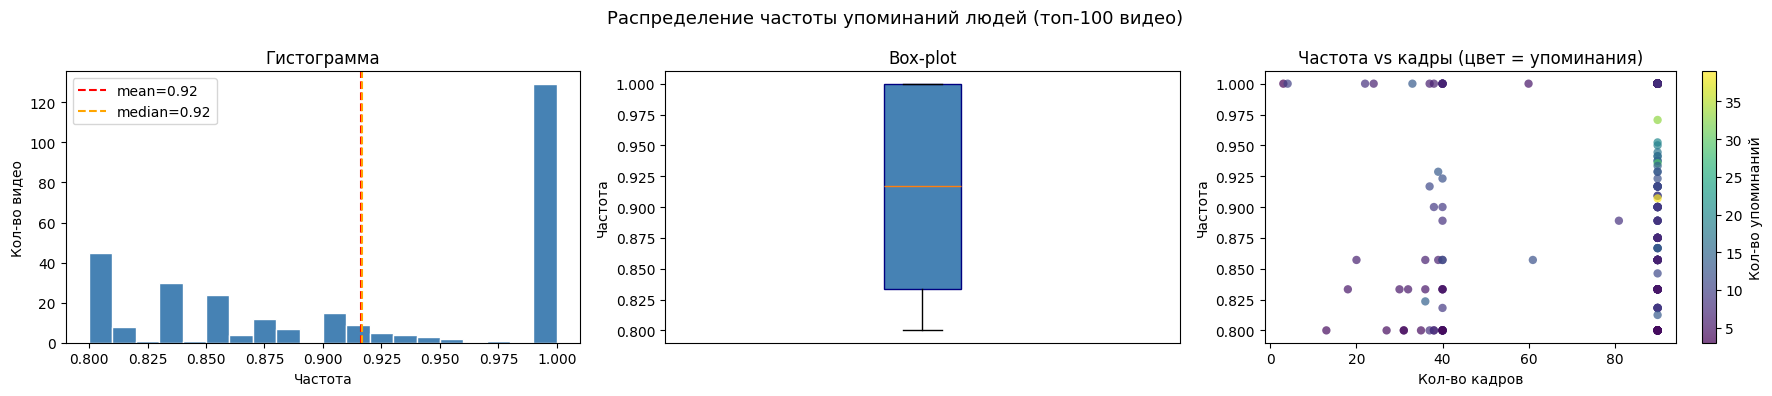

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
fig.suptitle("Распределение частоты упоминаний людей (топ-100 видео)", fontsize=13)

# 1. Гистограмма
axes[0].hist(freqs, bins=20, color="steelblue", edgecolor="white")
axes[0].axvline(freqs.mean(), color="red",    linestyle="--", label=f"mean={freqs.mean():.2f}")
axes[0].axvline(np.median(freqs), color="orange", linestyle="--", label=f"median={np.median(freqs):.2f}")
axes[0].set_xlabel("Частота")
axes[0].set_ylabel("Кол-во видео")
axes[0].set_title("Гистограмма")
axes[0].legend()

# 2. Box-plot
axes[1].boxplot(freqs, vert=True, patch_artist=True,
                boxprops=dict(facecolor="steelblue", color="navy"))
axes[1].set_ylabel("Частота")
axes[1].set_title("Box-plot")
axes[1].set_xticks([])

# 3. Scatter: частота vs кол-во кадров
sc = axes[2].scatter(
    df_top["n_frames"], df_top["frequency"],
    c=df_top["human_cnt"], cmap="viridis", alpha=0.7, edgecolors="none"
)
plt.colorbar(sc, ax=axes[2], label="Кол-во упоминаний")
axes[2].set_xlabel("Кол-во кадров")
axes[2].set_ylabel("Частота")
axes[2].set_title("Частота vs кадры (цвет = упоминания)")

plt.tight_layout()
plt.show()

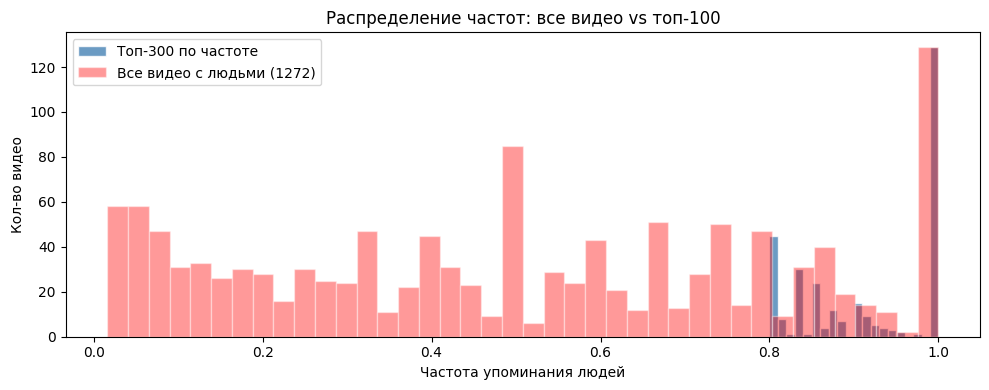

In [15]:
# Сравнение: топ-100 по частоте vs все видео с людьми
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(freqs, bins=20, color="steelblue",
        edgecolor="white", alpha=0.8, label="Топ-300 по частоте")
ax.hist(df_human["frequency"].values, bins=40, color="red", alpha=0.4,
        edgecolor="white", label="Все видео с людьми (1272)")
ax.set_xlabel("Частота упоминания людей")
ax.set_ylabel("Кол-во видео")
ax.set_title("Распределение частот: все видео vs топ-100")
ax.legend()
plt.tight_layout()
plt.show()

## Извлечение топ-100 из архива

In [16]:
EXTRACT_DST = "/home/jovyan/shares/SR006.nfs2/vashina/datasets/MeViS/data_sets/train/JPEGImages_fequency"
os.makedirs(EXTRACT_DST, exist_ok=True)

video_ids_top = df_top["vid_id"].tolist()
# Пути внутри tar-архива (не пути файловой системы!)
paths_to_extract = [f"JPEGImages/{vid_id}" for vid_id in video_ids_top]

cmd = ["tar", "-xf", TAR_PATH, "-C", EXTRACT_DST] + paths_to_extract
print(f"Извлекаем {len(paths_to_extract)} папок...")
print(f"Назначение: {EXTRACT_DST}")

result = subprocess.run(cmd, capture_output=True, text=True)
if result.returncode == 0:
    print("Готово!")
else:
    print("Ошибка:", result.stderr[:500])

Извлекаем 300 папок...
Назначение: /home/jovyan/shares/SR006.nfs2/vashina/datasets/MeViS/data_sets/train/JPEGImages_fequency


Готово!


## Интерактивный просмотрщик (Like / Skip)

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Папки лежат в EXTRACT_DST/JPEGImages/<vid_id> (tar распаковывает структуру как есть)
JPEG_VIEWER = os.path.join(EXTRACT_DST, "JPEGImages")

# Только реально распакованные папки
available = [
    row for _, row in df_top.iterrows()
    if os.path.exists(os.path.join(JPEG_VIEWER, row["vid_id"]))
]
print(f"Доступно для просмотра: {len(available)} видео")

state = {"idx": 0}

out           = widgets.Output()
counter_label = widgets.Label(value="")
like_btn      = widgets.Button(description="👍  Like",  button_style="success", layout=widgets.Layout(width="160px"))
skip_btn      = widgets.Button(description="⏭  Skip",  button_style="warning", layout=widgets.Layout(width="160px"))
buttons       = widgets.HBox([like_btn, skip_btn])

def show_current():
    idx = state["idx"]
    if idx >= len(available):
        with out:
            clear_output(wait=True)
            print("✅ Все видео просмотрены!")
            if os.path.exists(OUTPUT_TXT):
                liked = open(OUTPUT_TXT).read().splitlines()
                print(f"Лайкнуто: {len(liked)} видео → {OUTPUT_TXT}")
        like_btn.disabled = True
        skip_btn.disabled = True
        counter_label.value = "Готово!"
        return

    row    = available[idx]
    vid_id = row["vid_id"]
    counter_label.value = (
        f"Видео {idx + 1} / {len(available)}  |  "
        f"{vid_id}  |  "
        f"freq={row['frequency']:.2f}  "
        f"({int(row['human_cnt'])}/{int(row['total_exp'])} выражений)  "
        f"{int(row['n_frames'])} кадров"
    )

    src    = os.path.join(JPEG_VIEWER, vid_id)
    frames = sorted(os.listdir(src))
    selected = [frames[0], frames[len(frames) // 2], frames[-1]]
    labels   = ["Первый", "Средний", "Последний"]

    with out:
        clear_output(wait=True)
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        fig.suptitle(vid_id, fontsize=11)
        for ax, frame, label in zip(axes, selected, labels):
            img = mpimg.imread(os.path.join(src, frame))
            ax.imshow(img)
            ax.set_title(f"{label}\n{frame}", fontsize=9)
            ax.axis("off")
        plt.tight_layout()
        plt.show()

def on_like(b):
    vid_id = available[state["idx"]]["vid_id"]
    with open(OUTPUT_TXT, "a") as f:
        f.write(vid_id + "\n")
    state["idx"] += 1
    show_current()

def on_skip(b):
    state["idx"] += 1
    show_current()

like_btn.on_click(on_like)
skip_btn.on_click(on_skip)

display(counter_label, buttons, out)
show_current()

Доступно для просмотра: 300 видео


Label(value='')

Output()

 
стадия 1
1) выбрать подходящие видео из топ 300 
2) Выбрать те промты, у которых лишь один объект на сегментации. 
3) Создать bounding-box по этому объекту. для каждого кадра
4) составить промпт для детекции объекта для миницпм 

стадия 2
1) создать скрипт для 1-обработки изо 2-подсчета метрик, 3-(нужно логировать на каком кадре какого видео какой гт и какой предикт был )
2) прогнать тест по 100 фоткам -> посчитать метрики

стадия 3
1) прогнать скрипт по всем видосам

Ограничение этого датасета, что нету категорий у сегментации(Под категориями я имею ввиду, что категория 1 человек, категория 2 собака, категория 3 кружка). Есть только описание внутри expression, которые говорят о том, что именно сегментировано. И это неудобство. 

Временные оценки (3 сек/inference)
17 523 -- промпты с одним объектом
Сценарий	                    Промтов	    Время
Все 17 523 × 1 кадр	            17 523	    ~14.6 часов
Все 17 523 × все кадры (~67)	~1.17 млн	~41 день — нереально
300 видео × 1 кадр	            ~3 163	    ~2.6 часа
300 видео × все кадры	        ~212 000	~7.4 дней — тоже много

Сводная таблица для твоей выборки (150+150+150+30 видео)(видео где только люди/звери/смешанное/объекты)
Стратегия кадров	Инференсов	Время
Все кадры (~70)	    ~382 000	~4.4 дня
Каждый 10-й кадр	~38 000	    ~1.3 дня
5 кадров на промт	~27 000	    ~23 часа
3 кадра на промт	~16 000	    ~14 часов
1 кадр на промт	    ~5 500	    ~4.5 часа

Смешанные видео — 787 всего
Люди + животные (без объектов)	287
Люди + объекты (без животных)	261
Люди + животные + объекты	    239

HUMAN_KW  = ['person','man','woman','people','rider','girl','boy','child','human','men','women','hand','hands']

ANIMAL_KW = ['cat','dog','bird','rabbit','zebra','tiger','monkey','bear','fish','giraffe','elephant','sheep','panda','lizard','horse','cow','duck','deer','fox','wolf','lion','cheetah','leopard','gorilla','frog','turtle','snake','parrot','eagle','penguin','seal','whale','dolphin','camel','goat','pig','chicken','kangaroo','koala','crocodile','squirrel','hamster','mouse','rat','avian','creature','animal','beast','cub','pup','kitten','puppy']

OBJECT_KW = ['car','truck','bus','vehicle','motorcycle','bicycle','bike','boat','ship','plane','airplane','train','ball','balloon']



Я думаю, что смешанные видео — это то, что мне надо, потому что это как раз человек с кем-то присутствует и что-то делает. 